## Curso Integral de Econometría 
### Econometría de datos panel con Python
### Tema: Construcción de tabla de datos para un modelo panel dinámico
### Subtema: El ingreso y la convergencia económica en América Latina
### Sesión: 12
### Fecha: 18/11/2026
### Asesor: Alexis Adonai Morales Alberto

#### **Módulos, submódulos, clases y configuración**

In [2]:
!pip install wbgapi

Defaulting to user installation because normal site-packages is not writeable

   -------------------- ------------------- 1/2 [wbgapi]
   -------------------- ------------------- 1/2 [wbgapi]
   ---------------------------------------- 2/2 [wbgapi]




[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Modulos a utilizar 

import wbgapi as wb
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import statsmodels.api as sum

In [5]:
# Clases a utilizar 

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller
from scipy import stats
from pathlib import Path

In [7]:
# Configuración de la sesión 

BASE = Path(
    "E:\Econometrics Data Lab\Curso integral de econometría\Datos de panel\PANEL_SEP26"
)
SALIDA = BASE / "Resultados" / "S12_Datos_WB_Panel"
SALIDA.mkdir(parents=True, exist_ok=True)

# Sistema cromático 
EDL_FONDO = '#FFFFFF'
EDL_CREMA = '#F1ECE7'
EDL_TEXTO = '#222222'
EDL_APOYO = '#D3D3D3'
EDL_GRIS_CALIDO = '#6C6259'
EDL_NARANJA = '#F04A1D'
EDL_NARANJA_INV = '#A52F0D'

# Sistema categórico

EDL_NOMINAL = [
    '#F04A1D',  # Naranja (prioritaria)
    '#84517F',  # Ciruela
    '#65773E',  # Oliva
    '#B5790C',  # Ámbar
    '#A95D49',  # Terracota
    '#6C6259'   # Gris cálido
]

# Paleta divergente 

EDL_DIVERGENTE = [
    '#61365F', '#A775A0', '#DCC4D8',
    '#F3F0ED',
    '#F7B291', '#F04A1D', '#A52F0D'
]

cmap_divergente_edl = mcolors.LinearSegmentedColormap.from_list(
    'edl_div', EDL_DIVERGENTE
)

# Aplicar parámetros glovales para ambiente en matplotlib 

plt.rcParams.update({
    'figure.facecolor': EDL_FONDO,
    'axes.facecolor': EDL_FONDO,
    'axes.edgecolor': EDL_APOYO,
    'axes.linewidth': 0.8,
    'axes.labelcolor': EDL_TEXTO,
    'axes.titlecolor': EDL_TEXTO,
    'text.color': EDL_TEXTO,
    'xtick.color': EDL_TEXTO,
    'ytick.color': EDL_TEXTO,
    'grid.color': EDL_APOYO,
    'grid.linewidth': 0.6,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.sans-serif': ['DejaVu Sans', 'Arial'],
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10
})

#### **Carga de datos**

In [18]:
# Definir países (ISO-3)

paises = [
    'ARG', 'BRA', 'CHL', 'COL',
    'CRI', 'ECU', 'MEX', 'PER',
    'PYR', 'URY', 'PRI'
]

# Definir los años 

anios = range(2010, 2023)

# El diccionario de indicadores 

indicadores = {
    'NY.GDP.PCAP.KD': 'pib_pc',
    'NE.GDI.FTOT.ZS': 'inversion_fbkf',
    'NE.TRD.GNFS.ZS': 'apertura_comercial',
    'FP.CPI.TOTL.ZG': 'inflacion'
}

# Descarga de datos crutos desde la API del BM

df_crudo = wb.data.DataFrame(
    list(indicadores.keys()),
    economy=paises,
    time = anios,
    labels = False,
    numericTimeKeys=True
)

# Inspeccionar las primeras filas del formato
print("Estructura original descargada")
print(df_crudo.head())

Estructura original descargada
                                2010          2011  ...          2021          2022
economy series                                      ...                            
ARG     FP.CPI.TOTL.ZG           NaN           NaN  ...     48.409379     72.430758
        NE.GDI.FTOT.ZS     16.641466     17.248285  ...     17.290633     17.617790
        NE.TRD.GNFS.ZS     34.971013     35.206155  ...     33.078690     31.580179
        NY.GDP.PCAP.KD  13387.155375  14040.618912  ...  12549.281170  13276.823211
BRA     FP.CPI.TOTL.ZG      5.038727      6.636450  ...      8.301660      9.280106

[5 rows x 13 columns]


In [19]:
# Restructuración de los datos (pasar de formato ancho a largo)

df_largo = df_crudo.stack().unstack('series').reset_index()
df_largo = df_largo.rename(columns={'economy': 'pais', 'level_1': 'anio'})
df_largo = df_largo.rename(columns=indicadores)
df_largo['anio'] = df_largo['anio'].astype(int)
df_panel = df_largo.sort_values(by=['pais', 'anio']).reset_index(drop=True)
print("\nTabla transformada a estructura de panel (País - Año):")
print(df_panel.head(10))


Tabla transformada a estructura de panel (País - Año):
series pais  anio  inflacion  inversion_fbkf  apertura_comercial        pib_pc
0       ARG  2010        NaN       16.641466           34.971013  13387.155375
1       ARG  2011        NaN       17.248285           35.206155  14040.618912
2       ARG  2012        NaN       15.857525           30.526542  13754.425424
3       ARG  2013        NaN       16.289511           29.333929  13946.095083
4       ARG  2014        NaN       15.979954           28.406794  13456.131916
5       ARG  2015        NaN       15.564745           22.486226  13679.626498
6       ARG  2016        NaN       14.272363           26.093888  13265.886064
7       ARG  2017        NaN       15.162199           25.289601  13520.112985
8       ARG  2018  34.277224       15.251050           30.762536  13058.328545
9       ARG  2019  53.548304       14.199046           32.630615  12706.397811


In [20]:
df_panel

series,pais,anio,inflacion,inversion_fbkf,apertura_comercial,pib_pc
0,ARG,2010,NaN,16.641466,34.971013,13387.155375
1,ARG,2011,NaN,17.248285,35.206155,14040.618912
2,ARG,2012,NaN,15.857525,30.526542,13754.425424
3,ARG,2013,NaN,16.289511,29.333929,13946.095083
4,ARG,2014,NaN,15.979954,28.406794,13456.131916
...,...,...,...,...,...,...
125,URY,2018,7.606534,14.756135,47.791345,17608.944129
126,URY,2019,7.881989,14.491031,49.744866,17758.438427
127,URY,2020,9.756406,15.435719,47.731833,16443.363490
128,URY,2021,7.747914,17.671202,58.315056,17416.005231


#### **Transformaciones y creación del componente dinámico**

In [21]:
df_panel['ln_pib_pc'] = np.log(df_panel['pib_pc'])
df_panel['ln_pib_pc_rezagado'] = df_panel.groupby('pais')['ln_pib_pc'].shift(1)
print(df_panel[['pais', 'anio', 'ln_pib_pc', 'ln_pib_pc_rezagado']].head(15))

series pais  anio  ln_pib_pc  ln_pib_pc_rezagado
0       ARG  2010   9.502051                 NaN
1       ARG  2011   9.549710            9.502051
2       ARG  2012   9.529116            9.549710
3       ARG  2013   9.542955            9.529116
4       ARG  2014   9.507190            9.542955
5       ARG  2015   9.523663            9.507190
6       ARG  2016   9.492951            9.523663
7       ARG  2017   9.511934            9.492951
8       ARG  2018   9.477181            9.511934
9       ARG  2019   9.449861            9.477181
10      ARG  2020   9.340759            9.449861
11      ARG  2021   9.437419            9.340759
12      ARG  2022   9.493775            9.437419
13      BRA  2010   9.081670                 NaN
14      BRA  2011   9.112506            9.081670


#### **Verificación de balanceo**

In [22]:
variables_modelo = ['ln_pib_pc', 'ln_pib_pc_rezagado', 'inversion_fbkf', 'apertura_comercial', 'inflacion']
df_dinamico = df_panel.dropna(subset=variables_modelo).copy()

In [23]:
# Parámetros teóricos esperados

N_esperado = len(paises)
T_esperado = len(anios) - 1 
total_esperado = N_esperado * T_esperado

# Conteo real en tabla limpia

N_real = df_dinamico['pais'].nunique()
T_por_pais = df_dinamico.groupby('pais')['anio'].count()
saltos_temporales = df_dinamico.groupby('pais')['anio'].apply(lambda x: (x.diff().dropna() == 1).all())
print("--- REPORTE DE VERIFICACIÓN DE PANEL BALANCEADO ---")
print(f"Países únicos (N): {N_real} de {N_esperado} esperados.")
print(f"Periodos efectivos por país (T): {T_esperado} años (2011-2022).")
print(f"Observaciones totales (N x T): {len(df_dinamico)} de {total_esperado} esperadas.\n")

print("Conteo de observaciones válidas por país:")
print(T_por_pais)


--- REPORTE DE VERIFICACIÓN DE PANEL BALANCEADO ---
Países únicos (N): 9 de 11 esperados.
Periodos efectivos por país (T): 12 años (2011-2022).
Observaciones totales (N x T): 101 de 132 esperadas.

Conteo de observaciones válidas por país:
pais
ARG     5
BRA    12
CHL    12
COL    12
CRI    12
ECU    12
MEX    12
PER    12
URY    12
Name: anio, dtype: int64


In [24]:
# Condición de balanceo 

es_balanceado = (
    (len(df_dinamico) == total_esperado) and 
    (T_por_pais.nunique() == 1) and 
    (saltos_temporales.all())
)

print("\nRESULTADO DE LA PRUEBA:")
if es_balanceado:
    print("CONFIRMADO: El panel es ESTRICTAMENTE BALANCEADO y continuo (sin huecos temporales).")
else:
    print("ALERTA: El panel es DESBALANCEADO. Revisa países con datos faltantes:")
    print(T_por_pais[T_por_pais != T_esperado])


RESULTADO DE LA PRUEBA:
ALERTA: El panel es DESBALANCEADO. Revisa países con datos faltantes:
pais
ARG    5
Name: anio, dtype: int64


In [25]:
df_dinamico = df_dinamico[df_dinamico["pais"]!= "ARG"]

#### **Exportar datos para posteriores ejercicios y/o consultas**

In [26]:
df_dinamico.to_csv(
    SALIDA/"Datos_AL_Panel.csv",
    index = False,
    encoding = "utf-8",
    header = True
)

#### **Trayectorias temporales**

In [28]:
df_est = df_dinamico.reset_index().copy()

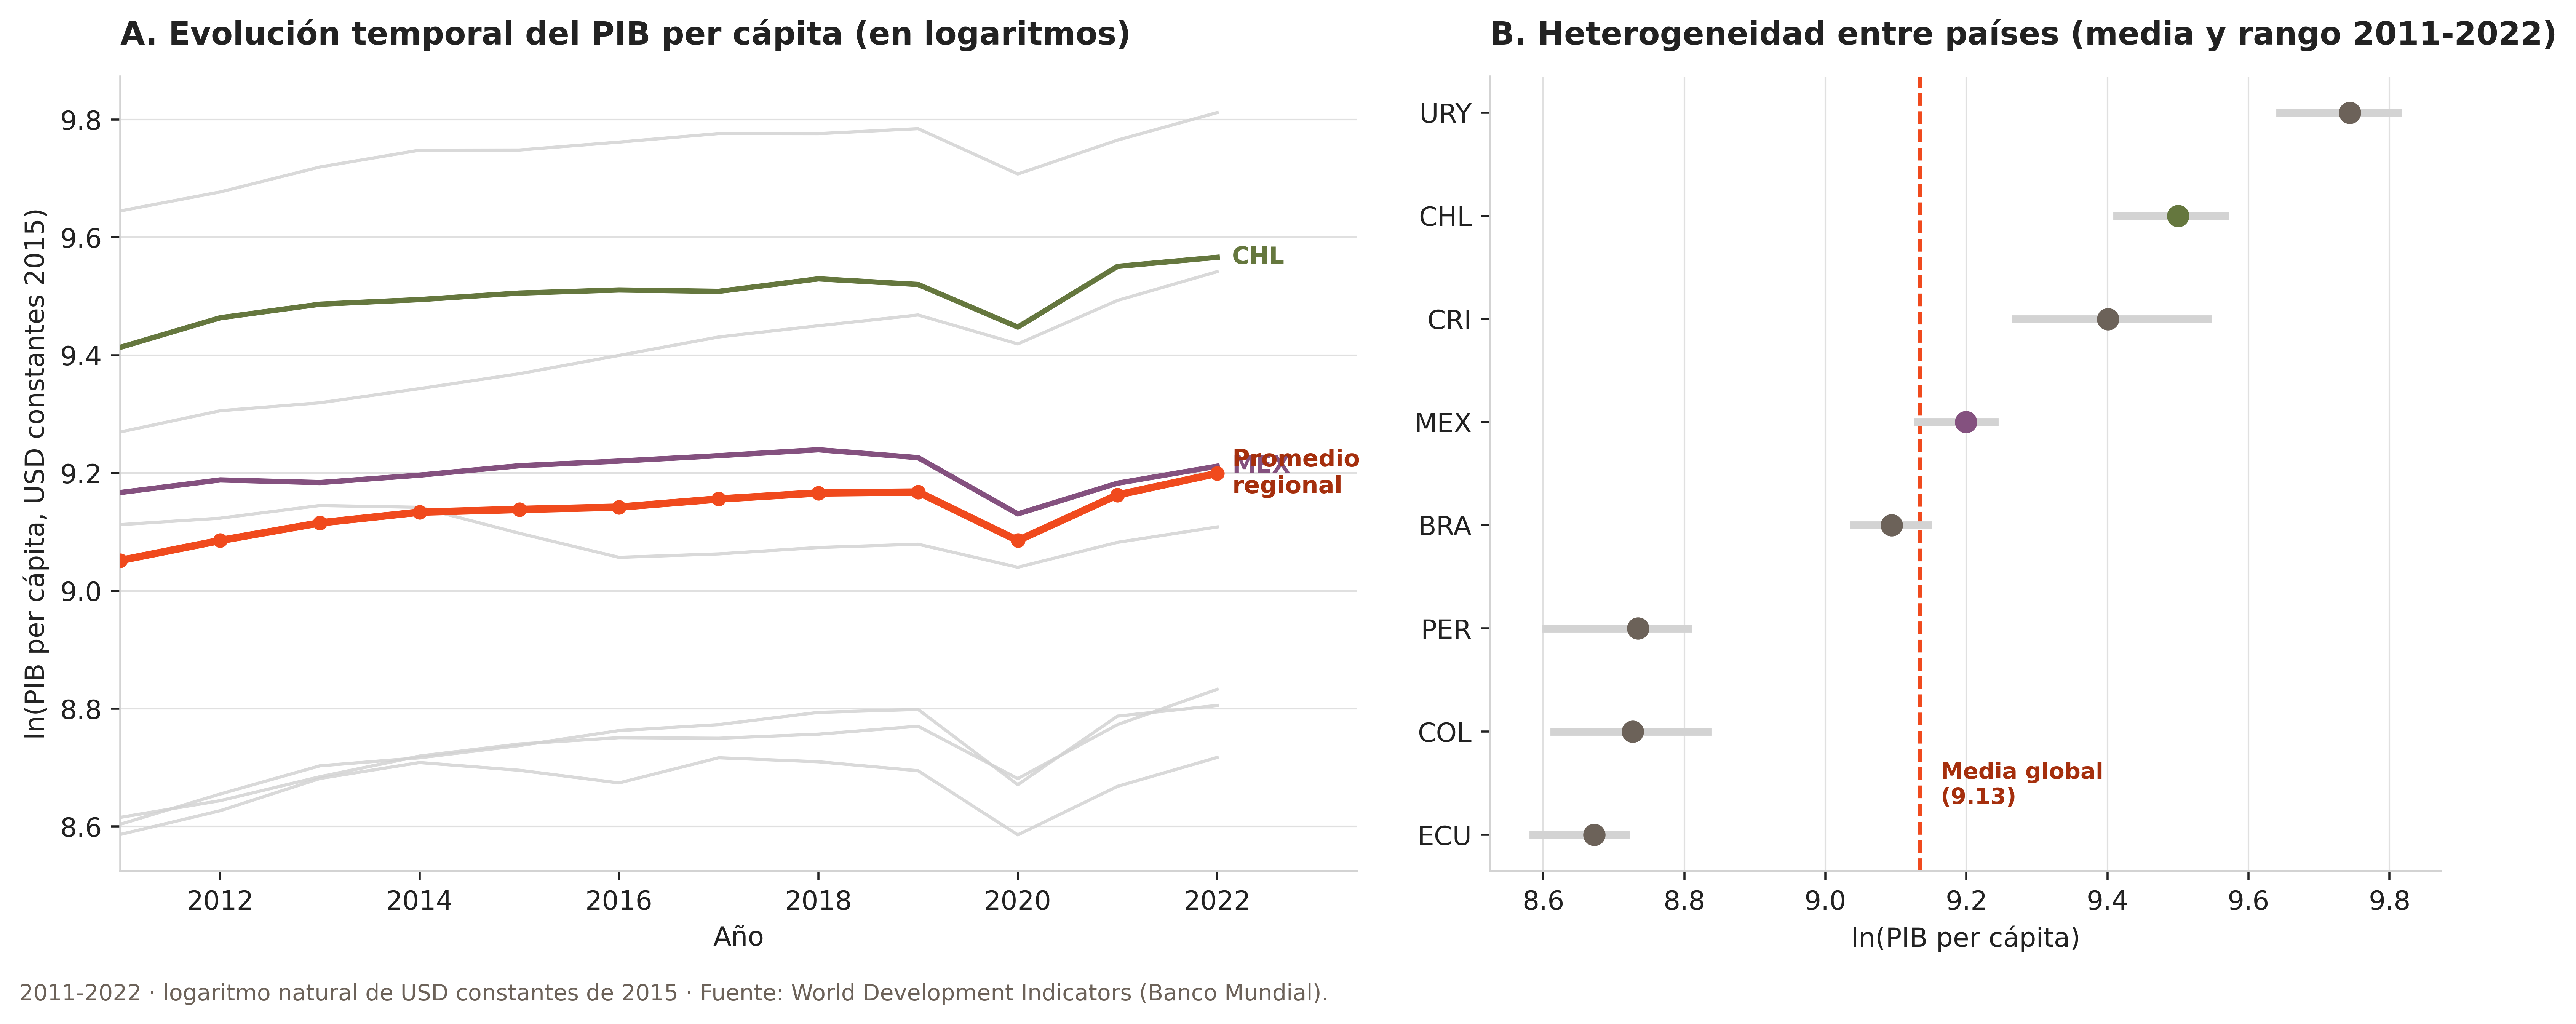

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.3, 1]}, dpi = 500)

ax1 = axes[0]
paises_destacados = {'MEX': ('#84517F', 'MEX'), 'CHL': ('#65773E', 'CHL')}

for pais in df_est['pais'].unique():
    sub = df_est[df_est['pais'] == pais]
    if pais not in paises_destacados:
        ax1.plot(sub['anio'], sub['ln_pib_pc'], color=EDL_APOYO, linewidth=1.2, alpha=0.85, zorder=1)

for pais, (color_p, etiqueta) in paises_destacados.items():
    sub = df_est[df_est['pais'] == pais]
    ax1.plot(sub['anio'], sub['ln_pib_pc'], color=color_p, linewidth=2.0, zorder=3)
    ax1.text(sub['anio'].iloc[-1] + 0.15, sub['ln_pib_pc'].iloc[-1], etiqueta,
             color=color_p, fontweight='bold', va='center', fontsize=9)

promedio_anual = df_est.groupby('anio')['ln_pib_pc'].mean()
ax1.plot(promedio_anual.index, promedio_anual.values, color=EDL_NARANJA,
         linewidth=2.8, marker='o', markersize=4.5, zorder=4)
ax1.text(promedio_anual.index[-1] + 0.15, promedio_anual.values[-1], 'Promedio\nregional',
         color=EDL_NARANJA_INV, fontweight='bold', va='center', fontsize=9)

ax1.set_title('A. Evolución temporal del PIB per cápita (en logaritmos)', loc='left', pad=12)
ax1.set_xlabel('Año')
ax1.set_ylabel('ln(PIB per cápita, USD constantes 2015)')
ax1.set_xlim(2011, 2023.4)
ax1.grid(axis='y', linestyle='-', alpha=0.7)

ax2 = axes[1]
resumen_pais = df_est.groupby('pais')['ln_pib_pc'].agg(['mean', 'min', 'max']).sort_values('mean')
media_global = df_est['ln_pib_pc'].mean()

ax2.axvline(media_global, color=EDL_NARANJA, linestyle='--', linewidth=1.3, zorder=1)
ax2.text(media_global + 0.03, 0.3, f'Media global\n({media_global:.2f})',
         color=EDL_NARANJA_INV, fontsize=8.5, fontweight='bold')

for idx, (pais, fila) in enumerate(resumen_pais.iterrows()):
    color_punto = paises_destacados[pais][0] if pais in paises_destacados else EDL_GRIS_CALIDO
    ax2.plot([fila['min'], fila['max']], [idx, idx], color=EDL_APOYO, linewidth=3.0, zorder=2)
    ax2.scatter(fila['mean'], idx, color=color_punto, s=55, zorder=3)

ax2.set_yticks(range(len(resumen_pais)))
ax2.set_yticklabels(resumen_pais.index)
ax2.set_title('B. Heterogeneidad entre países (media y rango 2011-2022)', loc='left', pad=12)
ax2.set_xlabel('ln(PIB per cápita)')
ax2.grid(axis='x', linestyle='-', alpha=0.7)

fig.text(0.01, -0.02, '2011-2022 · logaritmo natural de USD constantes de 2015 · Fuente: World Development Indicators (Banco Mundial).',
         fontsize=8.5, color=EDL_GRIS_CALIDO)
plt.tight_layout()
plt.show()